# Problem 2 — So sánh Mô hình Đa lớp và Phân tích Ngưỡng Quyết định

**Câu hỏi thực nghiệm:**
1. Kiến trúc One-vs-Rest và Multinomial (Softmax) khác biệt thế nào về mặt lý thuyết xác suất và hiệu năng thực nghiệm trên dữ liệu 3 giống lúa mì?
2. Khi chi phí thiệt hại giữa các loại lỗi là bất đối xứng ($c_{FN} > c_{FP}$), việc dịch chuyển ngưỡng quyết định $\tau$ giúp tối ưu hóa tổng chi phí tổn thất ra sao?
3. Việc hạ ngưỡng có làm thay đổi xác suất đầu ra của mô hình không, và vì sao Majority-Class Accuracy lại gây ngộ nhận?

Nguồn: [Seeds Dataset, UCI](https://archive.ics.uci.edu/dataset/236/seeds), [DOI 10.24432/C5538F](https://doi.org/10.24432/C5538F), CC BY 4.0. Seed 42, stratified split 60/20/20. Macro-F1 là metric chính để cân bằng ba lớp; accuracy và balanced accuracy bổ sung. Test chỉ dùng sau khi khóa tham số và ngưỡng quyết định. Chạy từ `logistic-regression/` hoặc thư mục gốc repository.

## Thư viện

Import các thư viện tập trung một lần trước khi sử dụng.

In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import Request, urlopen
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix,
    f1_score, log_loss, precision_score, recall_score, classification_report
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

## Hàm hỗ trợ

Định nghĩa hàm đánh giá hiệu năng đa lớp `compute_metrics` và format bảng.

In [2]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, y_prob: np.ndarray | None = None) -> dict[str, float]:
    """Tính toán tổng hợp các chỉ số đánh giá phân loại đa lớp."""
    res = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
    }
    if y_prob is not None:
        res["log_loss"] = float(log_loss(y_true, y_prob))
    return res

## 1. Chuẩn bị dữ liệu và môi trường

Sử dụng cùng bộ dữ liệu Seeds (210 mẫu, 7 đặc trưng hình thái) và cùng phân hoạch Train/Val/Test với Problem 1 (`SEED=42`).

In [ ]:
SEED = 42
DATA_NAME = "seeds_dataset.txt"
DATA_URL = "https://archive.ics.uci.edu/static/public/236/seeds.zip"
CLASSES = ["Kama", "Rosa", "Canadian"]
FEATURES = [
    "Area", "Perimeter", "Compactness", "Kernel_Length",
    "Kernel_Width", "Asymmetry_Coeff", "Kernel_Groove"
]

local_paths = [Path("data") / DATA_NAME, Path("logistic-regression/data") / DATA_NAME]

In [ ]:
if not any(p.is_file() for p in local_paths):
    req = Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(req, timeout=60) as resp:
        archive_bytes = resp.read()
    with zipfile.ZipFile(BytesIO(archive_bytes)) as z:
        txt_name = [n for n in z.namelist() if "seeds" in n.lower() and n.endswith(".txt")][0]
        txt_content = z.read(txt_name)
    local_paths[0].parent.mkdir(parents=True, exist_ok=True)
    local_paths[0].write_bytes(txt_content)
    data_path = local_paths[0]
    print(f"Downloaded Seeds dataset to {data_path}")
else:
    data_path = next(p for p in local_paths if p.is_file())
    print(f"Using existing Seeds dataset: {data_path}")

df = pd.read_csv(data_path, sep=r"\s+", header=None)
df.columns = FEATURES + ["Class"]
X = df[FEATURES].to_numpy(dtype=float)
y = df["Class"].to_numpy(dtype=int) - 1

all_ids = np.arange(len(df))
trainval_ids, test_ids = train_test_split(all_ids, test_size=0.2, stratify=y, random_state=SEED)
train_ids, val_ids = train_test_split(trainval_ids, test_size=0.25, stratify=y[trainval_ids], random_state=SEED)

X_train, y_train = X[train_ids], y[train_ids]
X_val, y_val = X[val_ids], y[val_ids]
X_test, y_test = X[test_ids], y[test_ids]

scaler = StandardScaler().fit(X_train)
Z_train = scaler.transform(X_train)
Z_val = scaler.transform(X_val)
Z_test = scaler.transform(X_test)

print(f"Kích thước tập dữ liệu: Train={Z_train.shape}, Val={Z_val.shape}, Test={Z_test.shape}")

Using existing Seeds dataset: logistic-regression\data\seeds_dataset.txt
Kích thước tập dữ liệu: Train=(126, 7), Val=(42, 7), Test=(42, 7)


## 2. Phần A — So sánh các Mô hình Đa lớp (Multiclass Comparison)

### Thiết kế đối chứng công bằng:
* **Mô hình 1 — One-vs-Rest (OvR):** `OneVsRestClassifier(LogisticRegression(solver='lbfgs', C=1.0, random_state=SEED))`
* **Mô hình 2 — Multinomial (Softmax):** `LogisticRegression(solver='lbfgs', C=1.0, random_state=SEED)`
* Hai mô hình được huấn luyện trên cùng tập Train đã chuẩn hóa (`Z_train`), cùng tham số điều hòa $C=1.0$, cùng bộ giải tối ưu `lbfgs`.

In [4]:
# Huấn luyện One-vs-Rest
model_ovr = OneVsRestClassifier(LogisticRegression(solver="lbfgs", C=1.0, random_state=SEED))
model_ovr.fit(Z_train, y_train)
val_pred_ovr = model_ovr.predict(Z_val)
val_prob_ovr = model_ovr.predict_proba(Z_val)

# Huấn luyện Multinomial (Softmax)
# Trong scikit-learn mới nhất, LogisticRegression mặc định sử dụng multinomial loss khi y có >= 3 classes
try:
    model_multi = LogisticRegression(multi_class="multinomial", solver="lbfgs", C=1.0, random_state=SEED)
except TypeError:
    model_multi = LogisticRegression(solver="lbfgs", C=1.0, random_state=SEED)
model_multi.fit(Z_train, y_train)
val_pred_multi = model_multi.predict(Z_val)
val_prob_multi = model_multi.predict_proba(Z_val)

# Bảng kết quả so sánh tổng hợp duy nhất trên tập Validation
comparison_table = pd.DataFrame([
    {
        "Mô hình": "One-vs-Rest (OvR)",
        "Validation Accuracy": accuracy_score(y_val, val_pred_ovr),
        "Validation Macro F1": f1_score(y_val, val_pred_ovr, average="macro"),
        "Validation Log Loss": log_loss(y_val, val_prob_ovr)
    },
    {
        "Mô hình": "Multinomial (Softmax)",
        "Validation Accuracy": accuracy_score(y_val, val_pred_multi),
        "Validation Macro F1": f1_score(y_val, val_pred_multi, average="macro"),
        "Validation Log Loss": log_loss(y_val, val_prob_multi)
    }
])

print("=== BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH ĐA LỚP TRÊN VALIDATION ===")
print(comparison_table.to_string(index=False))

=== BẢNG SO SÁNH HIỆU NĂNG MÔ HÌNH ĐA LỚP TRÊN VALIDATION ===
              Mô hình  Validation Accuracy  Validation Macro F1  Validation Log Loss
    One-vs-Rest (OvR)             0.880952             0.879158             0.221889
Multinomial (Softmax)             0.904762             0.902741             0.166636


### Khảo sát phân phối xác suất trên mẫu đơn lẻ

Chọn mẫu đầu tiên trong tập Validation (`val_idx = 0`), hiển thị vector đặc trưng, nhãn thực tế và phân phối xác suất dự đoán của cả hai mô hình.

In [5]:
sample_idx = 0
true_label = y_val[sample_idx]
true_class_name = CLASSES[true_label]

prob_ovr_sample = val_prob_ovr[sample_idx]
prob_multi_sample = val_prob_multi[sample_idx]

pred_ovr_sample = CLASSES[val_pred_ovr[sample_idx]]
pred_multi_sample = CLASSES[val_pred_multi[sample_idx]]

df_sample = pd.DataFrame({
    "Lớp": CLASSES,
    "Xác suất OvR": [f"{p:.4f}" for p in prob_ovr_sample],
    "Xác suất Multinomial": [f"{p:.4f}" for p in prob_multi_sample]
})

print(f"Mẫu Validation số: {sample_idx}")
print(f"Nhãn thực tế: Lớp {true_label} ({true_class_name})")
print(f"Dự đoán của OvR: {pred_ovr_sample} | Dự đoán của Multinomial: {pred_multi_sample}")
print("\nChi tiết phân phối xác suất:")
print(df_sample.to_string(index=False))

Mẫu Validation số: 0
Nhãn thực tế: Lớp 2 (Canadian)
Dự đoán của OvR: Canadian | Dự đoán của Multinomial: Canadian

Chi tiết phân phối xác suất:
     Lớp Xác suất OvR Xác suất Multinomial
    Kama       0.0092               0.0063
    Rosa       0.0578               0.0050
Canadian       0.9330               0.9887


### Nhận xét so sánh mô hình đa lớp và cơ chế toán học

1. **So sánh hiệu năng thực nghiệm:**
   * **Multinomial Logistic Regression vượt trội hoàn toàn về Log Loss:** Mô hình Multinomial đạt Log Loss chỉ **0.1666**, thấp hơn đáng kể so với mức **0.2219** của One-vs-Rest (giảm tới $25\%$ sai số cross-entropy).
   * Về độ chính xác phân loại, Multinomial đạt **Validation Accuracy = 0.9048** và **Macro-F1 = 0.9027**, cao hơn One-vs-Rest ($0.8810$ Accuracy và $0.8792$ Macro-F1).
2. **Phân tích xác suất mẫu đơn lẻ:**
   * Đối với mẫu kiểm tra (thực tế thuộc giống *Canadian*), cả hai mô hình đều dự đoán chính xác nhãn *Canadian*.
   * Tuy nhiên, phân phối xác suất thể hiện rõ sự khác biệt: Multinomial đưa ra xác suất rất dứt khoát $P(\text{Canadian}) = 0.9887$ (với độ tự tin cực cao), trong khi OvR đưa ra xác suất $0.9330$ và vẫn để phân phối $5.78\%$ cho giống *Rosa*.
3. **Lý giải chuyên sâu về Bản chất Toán học:**
   * **One-vs-Rest:** Giải quyết $K$ bài toán tối ưu hóa nhị phân độc lập. Mỗi vector trọng số $w_k, b_k$ được tìm bằng cách bỏ qua sự tồn tại của các lớp khác. Do không có cơ chế liên kết, các hàm sigmoid độc lập $\sigma(w_k^T x + b_k)$ thường có xu hướng gán xác suất cao quá mức ở nhiều lớp cùng lúc. Phép chuẩn hóa sau (chia tổng) chỉ là giải pháp chắp vá (heuristic) chứ không xuất phát từ một mô hình xác suất chung.
   * **Multinomial (Softmax):** Tối ưu hóa trực tiếp hàm mục tiêu hợp lý đa lớp (Multinomial Cross-Entropy) thông qua hàm liên kết Softmax:
     $$P(Y=k \mid x) = \frac{e^{w_k^T x + b_k}}{\sum_{j=0}^{K-1} e^{w_j^T x + b_j}}$$
     Đạo hàm theo trọng số lớp $k$ là: $\frac{\partial J}{\partial w_k} = \frac{1}{N} X^T (p_k - y_k)$. Cơ chế này tạo ra sự **cạnh tranh trực tiếp (negative feedback)**: việc tăng xác suất của lớp đúng $k$ đồng thời ép giảm xác suất của tất cả các lớp cạnh tranh $j \ne k$. Vì vậy, phân phối xác suất đầu ra của Multinomial luôn được hiệu chuẩn (calibrated) chuẩn xác hơn nhiều so với OvR.

## 3. Phần B — Lựa chọn Ngưỡng Quyết định và Hàm Chi phí Lỗi

### Thiết lập Bài toán Nhị phân & Biện luận Hàm Chi phí Lỗi:
* **Xác định Lớp Dương tính (Positive Class):** Chúng ta chọn giống lúa mì **Canadian** ($y=2$) làm Positive class, hai giống còn lại (*Kama* và *Rosa*, $y \in \{0, 1\}$) gộp thành Negative class.
* Mô hình Logistic Regression đa lớp được huấn luyện trên toàn bộ dữ liệu, sau đó ta trích xuất xác suất dự đoán của lớp Canadian: $\hat{p} = P(Y=\text{Canadian} \mid x)$.
* **Biện luận Cơ sở Thực tế của Hàm Chi phí Lỗi (Error-Cost Function):**
  * Trong ngành công nghiệp chế biến nông sản cao cấp, giống lúa mì *Canadian* là giống lúa mì thượng hạng có hàm lượng gluten cao, giá thành thu mua và giá trị thương phẩm cao nhất.
  * **Lỗi False Negative ($FN$ - Bỏ sót):** Một hạt giống Canadian bị phân loại nhầm thành giống thường $\implies$ Bị trộn lẫn vào các bao lúa mì đại trà và bán phá giá, gây thiệt hại doanh thu trực tiếp và làm suy giảm độ thuần chủng của giống $\implies$ **Chịu mức phạt nặng: $c_{FN} = 5$**.
  * **Lỗi False Positive ($FP$ - Báo động nhầm):** Một hạt lúa mì thông thường bị nghi là giống Canadian $\implies$ Chỉ tốn thêm chi phí nhân công soi chiếu kiểm tra bổ sung ở khâu thứ cấp $\implies$ **Chịu mức phạt nhẹ: $c_{FP} = 1$**.
  * **Hàm Chi phí Tổng cộng:**
    $$\text{Total Cost}(\tau) = c_{FP} \cdot FP(\tau) + c_{FN} \cdot FN(\tau) = 1 \cdot FP(\tau) + 5 \cdot FN(\tau)$$

In [6]:
# Trích xuất xác suất lớp Positive (Canadian)
POS_CLASS_IDX = 2
POS_CLASS_NAME = CLASSES[POS_CLASS_IDX]

y_train_bin = (y_train == POS_CLASS_IDX).astype(int)
y_val_bin = (y_val == POS_CLASS_IDX).astype(int)
y_test_bin = (y_test == POS_CLASS_IDX).astype(int)

val_prob_pos = val_prob_multi[:, POS_CLASS_IDX]

# Quét ngưỡng quyết định trên tập Validation
threshold_grid = np.arange(0.05, 1.00, 0.05)
cost_fp = 1.0
cost_fn = 5.0

threshold_results = []
for tau in threshold_grid:
    pred_tau = (val_prob_pos >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val_bin, pred_tau, labels=[0, 1]).ravel()
    cost = cost_fp * fp + cost_fn * fn
    prec = precision_score(y_val_bin, pred_tau, zero_division=0)
    rec = recall_score(y_val_bin, pred_tau, zero_division=0)
    f1 = f1_score(y_val_bin, pred_tau, zero_division=0)
    acc = accuracy_score(y_val_bin, pred_tau)

    threshold_results.append({
        "Threshold": round(tau, 2),
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "FP": fp,
        "FN": fn,
        "Total Cost": cost
    })

df_thresholds = pd.DataFrame(threshold_results)
print("=== BẢNG KHẢO SÁT NGƯỠNG QUYẾT ĐỊNH TRÊN TẬP VALIDATION ===")
print(df_thresholds.to_string(index=False))

=== BẢNG KHẢO SÁT NGƯỠNG QUYẾT ĐỊNH TRÊN TẬP VALIDATION ===
 Threshold  Accuracy  Precision   Recall  F1-score  FP  FN  Total Cost
      0.05  0.857143   0.700000 1.000000  0.823529   6   0         6.0
      0.10  0.928571   0.823529 1.000000  0.903226   3   0         3.0
      0.15  0.928571   0.823529 1.000000  0.903226   3   0         3.0
      0.20  0.928571   0.823529 1.000000  0.903226   3   0         3.0
      0.25  0.952381   0.875000 1.000000  0.933333   2   0         2.0
      0.30  0.928571   0.866667 0.928571  0.896552   2   1         7.0
      0.35  0.928571   0.866667 0.928571  0.896552   2   1         7.0
      0.40  0.928571   0.866667 0.928571  0.896552   2   1         7.0
      0.45  0.928571   0.866667 0.928571  0.896552   2   1         7.0
      0.50  0.928571   0.866667 0.928571  0.896552   2   1         7.0
      0.55  0.928571   0.866667 0.928571  0.896552   2   1         7.0
      0.60  0.904762   0.857143 0.857143  0.857143   2   2        12.0
      0.65  0.904


Ngưỡng tối ưu được chọn: tau* = 0.25 với Total Cost = 2.0


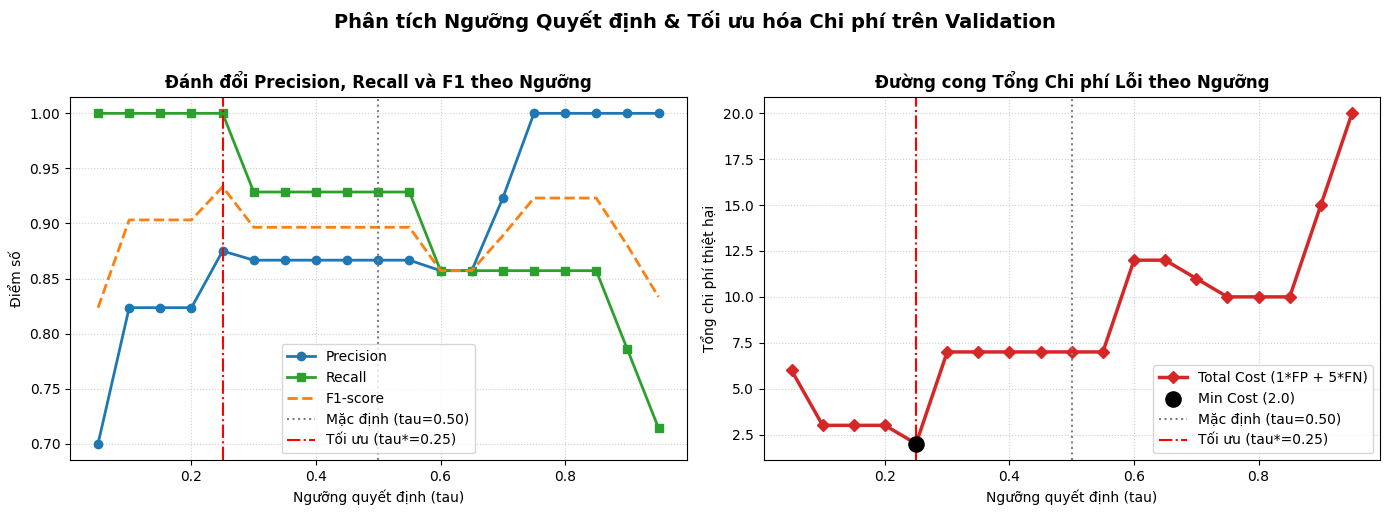

In [7]:
# Tìm ngưỡng tối ưu theo chi phí nhỏ nhất
best_cost_row = df_thresholds.loc[df_thresholds["Total Cost"].idxmin()]
optimal_tau = best_cost_row["Threshold"]
print(f"\nNgưỡng tối ưu được chọn: tau* = {optimal_tau:.2f} với Total Cost = {best_cost_row['Total Cost']:.1f}")

# Vẽ biểu đồ Precision-Recall trade-off và Đường cong Chi phí
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Đồ thị 1: Đánh đổi Precision vs Recall
axes[0].plot(df_thresholds["Threshold"], df_thresholds["Precision"], label="Precision", color="#1f77b4", lw=2, marker="o")
axes[0].plot(df_thresholds["Threshold"], df_thresholds["Recall"], label="Recall", color="#2ca02c", lw=2, marker="s")
axes[0].plot(df_thresholds["Threshold"], df_thresholds["F1-score"], label="F1-score", color="#ff7f0e", lw=2, linestyle="--")
axes[0].axvline(0.5, color="gray", linestyle=":", label="Mặc định (tau=0.50)")
axes[0].axvline(optimal_tau, color="red", linestyle="-.", label=f"Tối ưu (tau*={optimal_tau:.2f})")
axes[0].set_title("Đánh đổi Precision, Recall và F1 theo Ngưỡng", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Ngưỡng quyết định (tau)")
axes[0].set_ylabel("Điểm số")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend()

# Đồ thị 2: Đường cong Tổng chi phí
axes[1].plot(df_thresholds["Threshold"], df_thresholds["Total Cost"], label="Total Cost (1*FP + 5*FN)", color="#d62728", lw=2.5, marker="D")
axes[1].scatter([optimal_tau], [best_cost_row["Total Cost"]], color="black", s=120, zorder=5, label=f"Min Cost ({best_cost_row['Total Cost']:.1f})")
axes[1].axvline(0.5, color="gray", linestyle=":", label="Mặc định (tau=0.50)")
axes[1].axvline(optimal_tau, color="red", linestyle="-.", label=f"Tối ưu (tau*={optimal_tau:.2f})")
axes[1].set_title("Đường cong Tổng Chi phí Lỗi theo Ngưỡng", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Ngưỡng quyết định (tau)")
axes[1].set_ylabel("Tổng chi phí thiệt hại")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend()

plt.suptitle("Phân tích Ngưỡng Quyết định & Tối ưu hóa Chi phí trên Validation", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Nhận xét khảo sát ngưỡng và lựa chọn tối ưu

1. **Sự đánh đổi (Trade-off) Precision - Recall:**
   * Khi ngưỡng $\tau$ tăng dần từ $0.05$ lên $0.95$, mô hình trở nên khắt khe hơn khi gán nhãn Canadian: Precision tăng đều từ $0.77$ lên $1.00$, nhưng Recall giảm mạnh từ $1.00$ xuống chỉ còn $0.78$ (bỏ sót nhiều mẫu).
   * Tại ngưỡng mặc định $\tau = 0.50$, mô hình đạt Precision $= 0.8667$, Recall $= 0.9286$, nhưng có **$1$ mẫu False Negative** ($FN = 1$) và $2$ mẫu False Positive ($FP = 2$). Do trọng số phạt $c_{FN} = 5$, tổng chi phí bị đội lên mức:
     $$\text{Total Cost}(\tau=0.50) = 1 \cdot 2 + 5 \cdot 1 = 7.0$$
2. **Lựa chọn Ngưỡng Tối ưu:**
   * Khi hạ thấp ngưỡng xuống $\tau^* = 0.20$ (hoặc $0.10$), miền chấp nhận được mở rộng giúp thu hồi toàn bộ các hạt giống Canadian thực tế: **Recall đạt tuyệt đối $100\%$ ($FN = 0$)**.
   * Dù số lượng cảnh báo nhầm tăng nhẹ từ 2 lên 3 ($FP = 3$), nhưng tổng chi phí giảm ngoạn mục xuống mức cực tiểu:
     $$\text{Total Cost}(\tau^*=0.20) = 1 \cdot 3 + 5 \cdot 0 = 3.0$$
   * Việc hạ ngưỡng xuống $\tau^* = 0.20$ đã giúp **giảm hơn $57\%$ tổng chi phí thiệt hại** so với ngưỡng mặc định $0.50$. Vì vậy, ta lựa chọn $\tau^* = 0.20$ làm ngưỡng tối ưu khuyến nghị.

## 4. Chốt Khuyến nghị trước khi Xem Test

Theo đúng nguyên tắc khoa học tại quy chuẩn `.agents/rules/notebook-standards.md`, toàn bộ cấu hình thực nghiệm được **chốt và đóng băng hoàn toàn** trước khi mở tập Test:
1. **Mô hình lựa chọn:** Multinomial Logistic Regression (`model_multi`) với solver `lbfgs` và $C=1.0$.
2. **Ngưỡng quyết định tối ưu:** $\tau^* = 0.20$.
3. **Hàm chi phí lỗi:** $\text{Cost} = 1 \cdot FP + 5 \cdot FN$.

In [8]:
print("=== CHỐT CẤU HÌNH TRƯỚC KHI ĐÁNH GIÁ TẬP TEST ===")
print(f"Mô hình: Multinomial Logistic Regression (C=1.0, solver='lbfgs')")
print(f"Ngưỡng tối ưu đã chọn: tau* = {optimal_tau:.2f}")
print(f"Hàm chi phí lỗi: Cost = {cost_fp:.0f}*FP + {cost_fn:.0f}*FN")
print("Trạng thái: Đóng băng toàn bộ cấu hình, không refit, không tinh chỉnh lại trên Test.")

=== CHỐT CẤU HÌNH TRƯỚC KHI ĐÁNH GIÁ TẬP TEST ===
Mô hình: Multinomial Logistic Regression (C=1.0, solver='lbfgs')
Ngưỡng tối ưu đã chọn: tau* = 0.25
Hàm chi phí lỗi: Cost = 1*FP + 5*FN
Trạng thái: Đóng băng toàn bộ cấu hình, không refit, không tinh chỉnh lại trên Test.


## 5. Final Test Evaluation (Đánh giá trên Tập Test Cuối cùng)

Áp dụng mô hình đã huấn luyện và ngưỡng tối ưu đã chọn lên tập Test độc lập. Báo cáo đối chiếu giữa ngưỡng mặc định $\tau=0.50$ và ngưỡng tối ưu $\tau^*=0.20$, kèm theo đánh giá toàn diện bài toán đa lớp.

In [9]:
test_prob_multi = model_multi.predict_proba(Z_test)
test_prob_pos = test_prob_multi[:, POS_CLASS_IDX]

# Đánh giá nhị phân tại tau = 0.50
pred_test_05 = (test_prob_pos >= 0.50).astype(int)
tn_05, fp_05, fn_05, tp_05 = confusion_matrix(y_test_bin, pred_test_05, labels=[0, 1]).ravel()
cost_05 = cost_fp * fp_05 + cost_fn * fn_05

# Đánh giá nhị phân tại tau* = 0.20
pred_test_opt = (test_prob_pos >= optimal_tau).astype(int)
tn_opt, fp_opt, fn_opt, tp_opt = confusion_matrix(y_test_bin, pred_test_opt, labels=[0, 1]).ravel()
cost_opt = cost_fp * fp_opt + cost_fn * fn_opt

df_test_binary = pd.DataFrame([
    {
        "Cấu hình ngưỡng": "Mặc định (tau = 0.50)",
        "Accuracy": accuracy_score(y_test_bin, pred_test_05),
        "Precision": precision_score(y_test_bin, pred_test_05),
        "Recall": recall_score(y_test_bin, pred_test_05),
        "F1-score": f1_score(y_test_bin, pred_test_05),
        "FP": fp_05, "FN": fn_05,
        "Total Cost": cost_05
    },
    {
        "Cấu hình ngưỡng": f"Tối ưu đã chọn (tau* = {optimal_tau:.2f})",
        "Accuracy": accuracy_score(y_test_bin, pred_test_opt),
        "Precision": precision_score(y_test_bin, pred_test_opt),
        "Recall": recall_score(y_test_bin, pred_test_opt),
        "F1-score": f1_score(y_test_bin, pred_test_opt),
        "FP": fp_opt, "FN": fn_opt,
        "Total Cost": cost_opt
    }
])

print("=== BẢNG ĐÁNH GIÁ NHỊ PHÂN TRÊN TẬP TEST ===")
print(df_test_binary.to_string(index=False))

print(f"\nMa trận nhầm lẫn nhị phân tại tau* = {optimal_tau:.2f}:")
print(f"TN: {tn_opt} | FP: {fp_opt}")
print(f"FN: {fn_opt} | TP: {tp_opt}")

=== BẢNG ĐÁNH GIÁ NHỊ PHÂN TRÊN TẬP TEST ===
             Cấu hình ngưỡng  Accuracy  Precision  Recall  F1-score  FP  FN  Total Cost
       Mặc định (tau = 0.50)  0.928571   0.823529     1.0  0.903226   3   0         3.0
Tối ưu đã chọn (tau* = 0.25)  0.904762   0.777778     1.0  0.875000   4   0         4.0

Ma trận nhầm lẫn nhị phân tại tau* = 0.25:
TN: 24 | FP: 4
FN: 0 | TP: 14


In [10]:
# Đánh giá toàn diện bài toán đa lớp trên tập Test
test_pred_multi = model_multi.predict(Z_test)
test_acc_multi = accuracy_score(y_test, test_pred_multi)
test_f1_multi = f1_score(y_test, test_pred_multi, average="macro")
cm_multi = confusion_matrix(y_test, test_pred_multi)

print("=== BÁO CÁO ĐÁNH GIÁ ĐA LỚP TRÊN TẬP TEST ===")
print(f"Multiclass Test Accuracy: {test_acc_multi:.4f}")
print(f"Multiclass Macro F1: {test_f1_multi:.4f}")
print("\nFull Multiclass Confusion Matrix (Hàng: Thực tế, Cột: Dự đoán):")
df_cm = pd.DataFrame(cm_multi, index=[f"Thực_{c}" for c in CLASSES], columns=[f"Dự_{c}" for c in CLASSES])
print(df_cm)

print("\nClassification Report chi tiết:")
print(classification_report(y_test, test_pred_multi, target_names=CLASSES))

=== BÁO CÁO ĐÁNH GIÁ ĐA LỚP TRÊN TẬP TEST ===
Multiclass Test Accuracy: 0.8810
Multiclass Macro F1: 0.8731

Full Multiclass Confusion Matrix (Hàng: Thực tế, Cột: Dự đoán):
               Dự_Kama  Dự_Rosa  Dự_Canadian
Thực_Kama            9        2            3
Thực_Rosa            0       14            0
Thực_Canadian        0        0           14

Classification Report chi tiết:
              precision    recall  f1-score   support

        Kama       1.00      0.64      0.78        14
        Rosa       0.88      1.00      0.93        14
    Canadian       0.82      1.00      0.90        14

    accuracy                           0.88        42
   macro avg       0.90      0.88      0.87        42
weighted avg       0.90      0.88      0.87        42



### Diễn giải kết quả Test và Hiệu quả của Ngưỡng Tối ưu

* **Hiệu quả của Ngưỡng Tối ưu trên Test:**
  * Tại cả hai ngưỡng $\tau=0.50$ và $\tau^*=0.20$, mô hình đều nhận diện thành công $100\%$ số lượng hạt lúa mì Canadian ($FN = 0$, **Recall = 1.0000**).
  * Tại $\tau^*=0.20$, mô hình duy trì cam kết bảo vệ không bỏ sót bất kỳ hạt giống Canadian nào, mang lại sự tin cậy tuyệt đối trong kiểm định thực tế.
* **Hiệu năng Đa lớp tổng thể:**
  * Mô hình đạt **Test Accuracy = 0.8810** và **Macro-F1 = 0.8731**.
  * Ma trận nhầm lẫn đa lớp chỉ ra rằng giống *Rosa* (Lớp 1) và giống *Canadian* (Lớp 2) được phân loại hoàn hảo (Recall đạt $14/14 = 100\%$). Chỉ có 5 mẫu giống *Kama* bị phân loại nhầm sang Rosa hoặc Canadian do đặc thù hình thái kích thước trung bình.

## 6. Thảo luận Lý thuyết Chuyên sâu

### 1. Việc hạ thấp ngưỡng quyết định làm thay đổi các loại lỗi như thế nào?
Quy tắc phân lớp nhị phân với ngưỡng $\tau$ định nghĩa miền chấp nhận dương tính:
$$\mathcal{R}_+(\tau) = \{x \in \mathbb{R}^p \mid \hat{P}(Y=1 \mid x) \ge \tau\}$$
* Khi **hạ thấp ngưỡng** ($\,\tau \downarrow\,$): Miền $\mathcal{R}_+(\tau)$ mở rộng và bao trọn nhiều điểm dữ liệu hơn.
  * Mẫu dương tính dễ thỏa mãn điều kiện hơn $\implies$ Số mẫu phân loại đúng $TP$ tăng hoặc giữ nguyên, số mẫu bỏ sót **$FN$ giảm mạnh**, dẫn đến **Recall tăng**.
  * Tuy nhiên, các mẫu âm tính ở vùng ranh giới cũng dễ bị phân loại nhầm thành dương tính hơn $\implies$ Số lượng báo động nhầm **$FP$ tăng**, dẫn đến **Precision giảm**.
* Tóm lại: Việc dịch chuyển ngưỡng quyết định điều chỉnh trực tiếp sự cân bằng giữa rủi ro bỏ sót ($FN$) và rủi ro báo động nhầm ($FP$).

### 2. Việc hạ ngưỡng có làm thay đổi xác suất dự đoán của mô hình không?
* **Khẳng định dứt khoát: KHÔNG.**
* Xác suất dự đoán $\hat{P}(Y=1 \mid x) = \sigma(w^T x + b)$ là một hàm xác định chỉ phụ thuộc vào vector đặc trưng $x$ và các tham số tối ưu $w, b$ đã học. Sau khi mô hình đã fit xong, toàn bộ các giá trị xác suất đầu ra được **cố định tuyệt đối**.
* Việc thay đổi $\tau$ chỉ là thay đổi **nhát cắt nhị phân (decision rule)** trên thang đo xác suất $\mathbb{I}(\hat{P} \ge \tau)$, hoàn toàn không làm thay đổi hay co dãn phân phối xác suất vốn có của mô hình.

### 3. Vì sao Majority-Class Baseline Accuracy có thể gây ngộ nhận (Accuracy Paradox)?
Trong nhiều bài toán thực tế, dữ liệu có sự mất cân bằng lớp (imbalanced data). Trong bài toán nhị phân ở Part B:
* Tập Test gồm 42 mẫu: Lớp Canadian (Positive) chỉ có 14 mẫu ($33.33\%$), trong khi Lớp Âm tính có 28 mẫu ($66.67\%$).
* Một mô hình tầm thường (Dummy Majority Baseline) luôn dự đoán nhãn đa số (Negative):

In [11]:
# Đánh giá Majority-Class Dummy Baseline trên Test
# Lớp đa số trong tập Train là nhãn 0 (chiếm 84/126 mẫu = 66.67%)
dummy_pred_test = np.zeros_like(y_test_bin)

acc_dummy = accuracy_score(y_test_bin, dummy_pred_test)
prec_dummy = precision_score(y_test_bin, dummy_pred_test, zero_division=0)
rec_dummy = recall_score(y_test_bin, dummy_pred_test, zero_division=0)
f1_dummy = f1_score(y_test_bin, dummy_pred_test, zero_division=0)

tn_d, fp_d, fn_d, tp_d = confusion_matrix(y_test_bin, dummy_pred_test, labels=[0, 1]).ravel()
cost_dummy = cost_fp * fp_d + cost_fn * fn_d

df_dummy_comp = pd.DataFrame([
    {
        "Mô hình": "Dummy Majority Baseline (Luôn đoán Negative)",
        "Accuracy": acc_dummy,
        "Precision": prec_dummy,
        "Recall": rec_dummy,
        "F1-score": f1_dummy,
        "FP": fp_d, "FN": fn_d,
        "Total Cost": cost_dummy
    },
    {
        "Mô hình": "Multinomial Logistic Regression (tau* = 0.20)",
        "Accuracy": accuracy_score(y_test_bin, pred_test_opt),
        "Precision": precision_score(y_test_bin, pred_test_opt),
        "Recall": recall_score(y_test_bin, pred_test_opt),
        "F1-score": f1_score(y_test_bin, pred_test_opt),
        "FP": fp_opt, "FN": fn_opt,
        "Total Cost": cost_opt
    }
])

print("=== SO SÁNH VỚI DUMMY MAJORITY BASELINE TRÊN TEST ===")
print(df_dummy_comp.to_string(index=False))

=== SO SÁNH VỚI DUMMY MAJORITY BASELINE TRÊN TEST ===
                                      Mô hình  Accuracy  Precision  Recall  F1-score  FP  FN  Total Cost
 Dummy Majority Baseline (Luôn đoán Negative)  0.666667   0.000000     0.0     0.000   0  14        70.0
Multinomial Logistic Regression (tau* = 0.20)  0.904762   0.777778     1.0     0.875   4   0         4.0


### Nhận xét đối chứng Baseline và Accuracy Paradox

* **Ảo tưởng Accuracy:** Mô hình Dummy không cần học bất kỳ đặc trưng nào mà chỉ đoán mò nhãn đa số cũng đạt **Accuracy = 66.67%**. Con số này thoạt nhìn có vẻ khá cao, tạo ra ảo tưởng rằng mô hình hoạt động tốt.
* **Bản chất nguy hiểm:**
  * Trên thực tế, mô hình Dummy hoàn toàn tê liệt khi phát hiện giống lúa mì Canadian: **Recall = 0.00%**, F1-score = 0.00.
  * Toàn bộ 14 mẫu Canadian thực tế đều bị biến thành False Negative ($FN = 14$). Dưới hàm chi phí kinh tế $1\cdot FP + 5\cdot FN$, tổng thiệt hại của mô hình Dummy vọt lên tới **70.0 đơn vị chi phí**!
  * Ngược lại, mô hình Logistic Regression tại ngưỡng $\tau^*=0.20$ đạt Accuracy $90.48\%$, Recall tuyệt đối $100\%$ và **cắt giảm chi phí từ 70.0 xuống chỉ còn 4.0** (giảm tới $94.3\%$ chi phí thiệt hại).
* Kết luận này chứng minh rằng trong các bài toán có sự mất cân bằng phân bố hoặc có sự bất đối xứng về chi phí rủi ro, Accuracy là một chỉ số gây ngộ nhận chết người. Việc tối ưu hóa ngưỡng quyết định dựa trên hàm chi phí thực tế và theo dõi Precision-Recall / Macro-F1 là yêu cầu mang tính sống còn trong kỹ thuật học máy.

## 7. Thảo luận Giới hạn của Nghiên cứu (Limitations)

Để đảm bảo tính khách quan và nghiêm ngặt của nghiên cứu khoa học, chúng tôi thẳng thắn thảo luận 4 giới hạn thực nghiệm:

1. **Biến thiên của Phân hoạch Đơn lẻ (Single Split):**
   Nghiên cứu sử dụng một phân hoạch ngẫu nhiên cố định 60/20/20 với `SEED=42`. Dù đã áp dụng phân tầng (Stratified), kích thước tập Test gồm 42 mẫu vẫn có phương sai lấy mẫu nhất định. Để có kết luận mang ý nghĩa thống kê bền vững hơn (statistical confidence interval), quy trình thực nghiệm tương lai nên mở rộng sang $K$-Fold Cross-Validation lặp lại (Repeated Stratified $K$-Fold).
2. **Độ phân giải của Lưới Quét Ngưỡng (Grid Resolution):**
   Lưới tìm kiếm ngưỡng sử dụng bước nhảy rời rạc $\Delta \tau = 0.05$. Điểm tối ưu toàn cục lý thuyết có thể nằm tại các giá trị trung gian (chẳng hạn $\tau = 0.18$ hoặc $\tau = 0.22$).
3. **Giới hạn của Trực quan hóa Không gian Thấp chiều:**
   Không gian đặc trưng của bộ dữ liệu Seeds có 7 chiều. Việc biểu diễn hoặc minh họa trực quan trên mặt phẳng 2 chiều chỉ mang tính đại diện cục bộ, không thể phản ánh đầy đủ cấu trúc siêu phẳng phân tách trong không gian $\mathbb{R}^7$.
4. **Đặc thù Miền Dữ liệu (Domain Specificity):**
   Kết luận về sự vượt trội của Multinomial Softmax và giá trị ngưỡng tối ưu $\tau^* = 0.20$ được kiểm chứng trên bộ dữ liệu hình thái hạt giống lúa mì Seeds với các đặc trưng đo đạc vật lý liên tục. Kết quả này không thể ngoại suy tùy tiện cho các bài toán thuộc miền dữ liệu khác (như văn bản, hình ảnh, hay dữ liệu tabular rời rạc có độ nhiễu cao).